<u><h1><b><center>CO2 EMISSION BY VEHICLES</center></b></h1></u>

<p style="font-family: 'Times New Roman', Times, serif;"><b><h3 align='right'>PRESENTED BY: MUHAMMED ADHIL P</h3></b></p>


<h4><b><u>INTRODUCTION</u></b></h4>

<b>OBJECTIVE:- To determine the CO2 Emissions(g/km)<br>
TYPE OF PROBLEM:- Regression problem.</b>

<b>MODELS USED</u><br>
   <b> &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- LINEAR REGRESSION<br>
    &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- RANDOM FOREST REGRESSOR<br>
    &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;- DECISION TREE REGRESSOR<br></b></p>

<h4><u><b>LIBRARY IMPORTS:-</b></u></h4>

In [6]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error,accuracy_score,mean_absolute_error
import matplotlib.pyplot as plt
%matplotlib inline

<u><h4><b>READ DATASET:-</b></h3></u>

In [8]:
df=pd.read_csv(r"C:\DATA ANALATICS\ADHIL PROJECTS\ML PROJECT\CO2 Emissions_Canada.csv")
df

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
...,...,...,...,...,...,...,...,...,...,...,...,...
7380,VOLVO,XC40 T5 AWD,SUV - SMALL,2.0,4,AS8,Z,10.7,7.7,9.4,30,219
7381,VOLVO,XC60 T5 AWD,SUV - SMALL,2.0,4,AS8,Z,11.2,8.3,9.9,29,232
7382,VOLVO,XC60 T6 AWD,SUV - SMALL,2.0,4,AS8,Z,11.7,8.6,10.3,27,240
7383,VOLVO,XC90 T5 AWD,SUV - STANDARD,2.0,4,AS8,Z,11.2,8.3,9.9,29,232


<h4><b><u>DATASET OVERVIEW</u></b></h4>
<b>DATA SIZE: [7385,12]</b><br>
<b>DATA SOURCE: KAGGLE</b>

In [9]:
# no.of rows and columns
print("We have",df.shape[0],"rows and",df.shape[1],"columns")

We have 7385 rows and 12 columns


In [10]:
print(df.dtypes)

Make                                 object
Model                                object
Vehicle Class                        object
Engine Size(L)                      float64
Cylinders                             int64
Transmission                         object
Fuel Type                            object
Fuel Consumption City (L/100 km)    float64
Fuel Consumption Hwy (L/100 km)     float64
Fuel Consumption Comb (L/100 km)    float64
Fuel Consumption Comb (mpg)           int64
CO2 Emissions(g/km)                   int64
dtype: object


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              7385 non-null   object 
 1   Model                             7385 non-null   object 
 2   Vehicle Class                     7385 non-null   object 
 3   Engine Size(L)                    7385 non-null   float64
 4   Cylinders                         7385 non-null   int64  
 5   Transmission                      7385 non-null   object 
 6   Fuel Type                         7385 non-null   object 
 7   Fuel Consumption City (L/100 km)  7385 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   7385 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  7385 non-null   float64
 10  Fuel Consumption Comb (mpg)       7385 non-null   int64  
 11  CO2 Emissions(g/km)               7385 non-null   int64  
dtypes: flo

In [12]:
df.describe()

,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
count,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000
mean,3.160068,5.615030,12.556534,9.041706,10.975071,27.481652,250.584699
std,1.354170,1.828307,3.500274,2.224456,2.892506,7.231879,58.512679
min,0.900000,3.000000,4.200000,4.000000,4.100000,11.000000,96.000000
25%,2.000000,4.000000,10.100000,7.500000,8.900000,22.000000,208.000000
50%,3.000000,6.000000,12.100000,8.700000,10.600000,27.000000,246.000000
75%,3.700000,6.000000,14.600000,10.200000,12.600000,32.000000,288.000000
max,8.400000,16.000000,30.600000,20.600000,26.100000,69.000000,522.000000


<b>CHECK FOR NaN:-</b>

In [13]:
df.isnull().sum()

Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64

In [14]:
df.columns

Index(['Make', 'Model', 'Vehicle Class', 'Engine Size(L)', 'Cylinders',
       'Transmission', 'Fuel Type', 'Fuel Consumption City (L/100 km)',
       'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)',
       'Fuel Consumption Comb (mpg)', 'CO2 Emissions(g/km)'],
      dtype='object')

In [15]:
df.columns = df.columns.str.replace(" ", "_")
df.columns = df.columns.str.lower()
df.columns

Index(['make', 'model', 'vehicle_class', 'engine_size(l)', 'cylinders',
       'transmission', 'fuel_type', 'fuel_consumption_city_(l/100_km)',
       'fuel_consumption_hwy_(l/100_km)', 'fuel_consumption_comb_(l/100_km)',
       'fuel_consumption_comb_(mpg)', 'co2_emissions(g/km)'],
      dtype='object')

<b>HANDLING NON-NUMERIC COLUMNS:-</B>

__LABEL ENCODING__

In [16]:
from sklearn.preprocessing import LabelEncoder
label_encoder=LabelEncoder()

dfle=df
dfle.make=label_encoder.fit_transform(dfle.make)
dfle.model=label_encoder.fit_transform(dfle.model)
dfle.vehicle_class=label_encoder.fit_transform(dfle.vehicle_class)
dfle.transmission=label_encoder.fit_transform(dfle.transmission)
dfle.fuel_type=label_encoder.fit_transform(dfle.fuel_type)
dfle

,make,model,vehicle_class,engine_size(l),cylinders,transmission,fuel_type,fuel_consumption_city_(l/100_km),fuel_consumption_hwy_(l/100_km),fuel_consumption_comb_(l/100_km),fuel_consumption_comb_(mpg),co2_emissions(g/km)
0,0,1057,0,2.0,4,14,4,9.9,6.7,8.5,33,196
1,0,1057,0,2.4,4,25,4,11.2,7.7,9.6,29,221
2,0,1058,0,1.5,4,22,4,6.0,5.8,5.9,48,136
3,0,1233,11,3.5,6,15,4,12.7,9.1,11.1,25,255
4,0,1499,11,3.5,6,15,4,12.1,8.7,10.6,27,244
...,...,...,...,...,...,...,...,...,...,...,...,...
7380,41,1951,11,2.0,4,17,4,10.7,7.7,9.4,30,219
7381,41,1957,11,2.0,4,17,4,11.2,8.3,9.9,29,232
7382,41,1960,11,2.0,4,17,4,11.7,8.6,10.3,27,240
7383,41,1968,12,2.0,4,17,4,11.2,8.3,9.9,29,232


<b><h4><u>DATA VISUALIZATION:</u></h4></b>

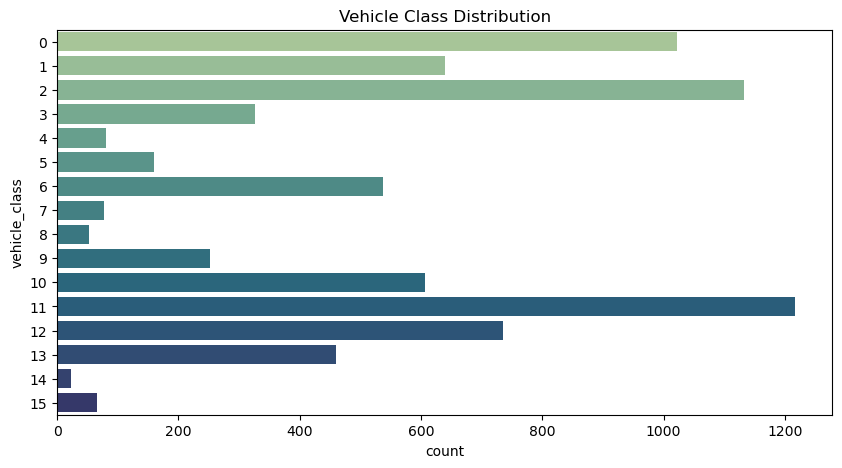

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='vehicle_class',hue='vehicle_class', palette='crest',legend=False)
plt.title('Vehicle Class Distribution')
plt.show()

<h4><b>CORRELATION AND HEATMAP</b></h4>

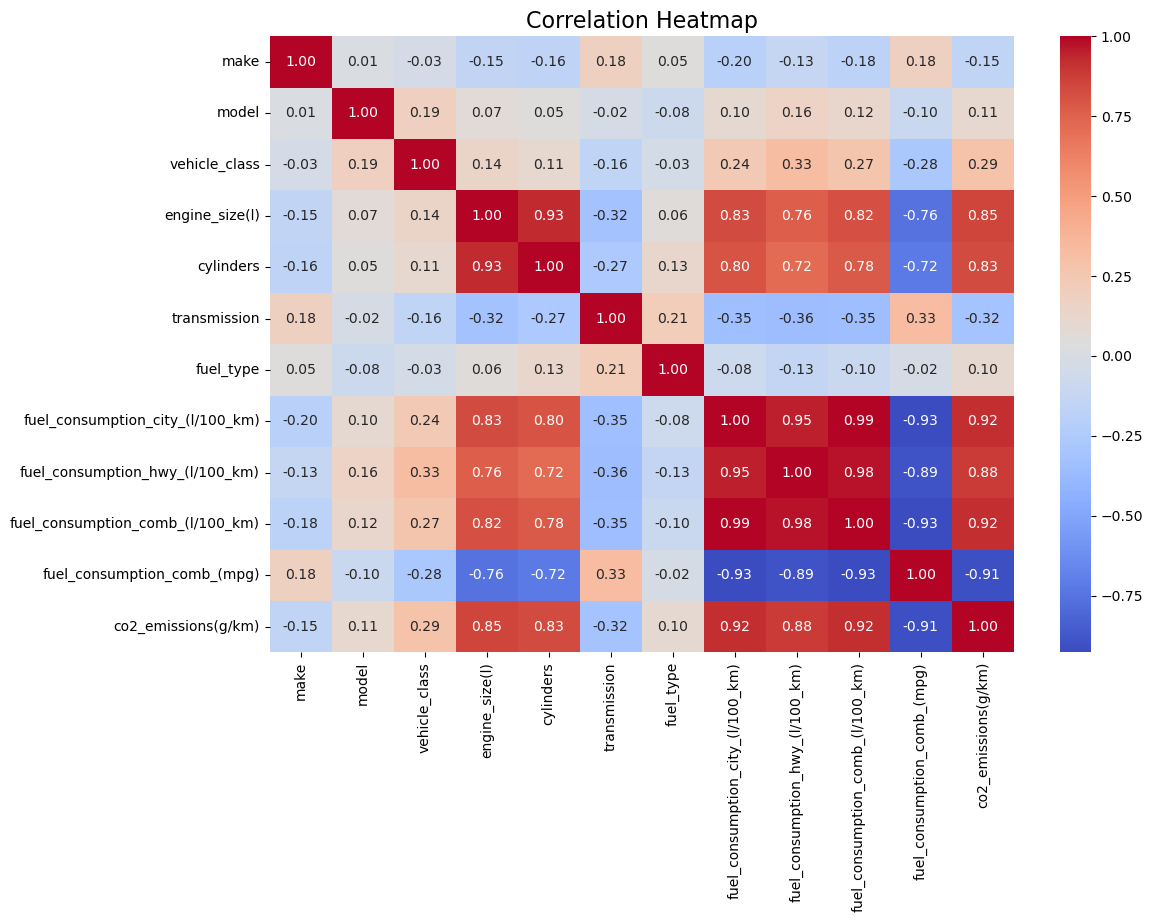

In [18]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap", fontsize=16)
plt.show()

<h4><b>HISTOGRAM WITH KDE (Kernel Density Estimate)</b></h4>

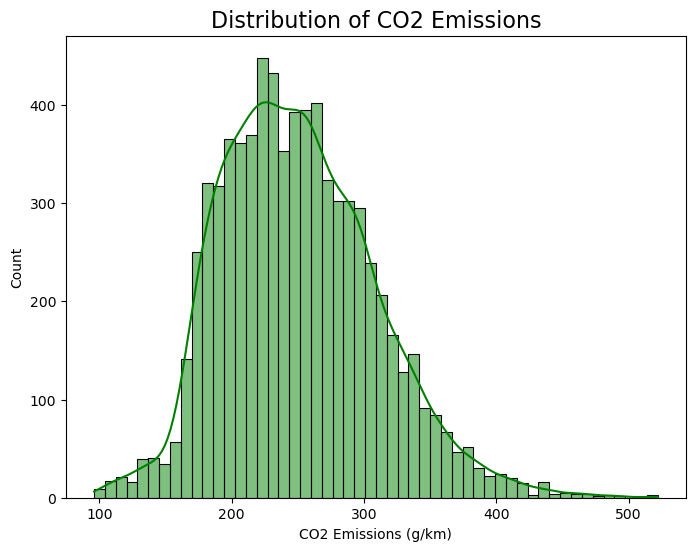

In [19]:
# Target Variable Distribution
plt.figure(figsize=(8,6))
sns.histplot(df['co2_emissions(g/km)'], kde=True, color="green")
plt.title("Distribution of CO2 Emissions", fontsize=16)
plt.xlabel("CO2 Emissions (g/km)")
plt.ylabel("Count")
plt.show()


<h4><b>BOX PLOT</b></h4>

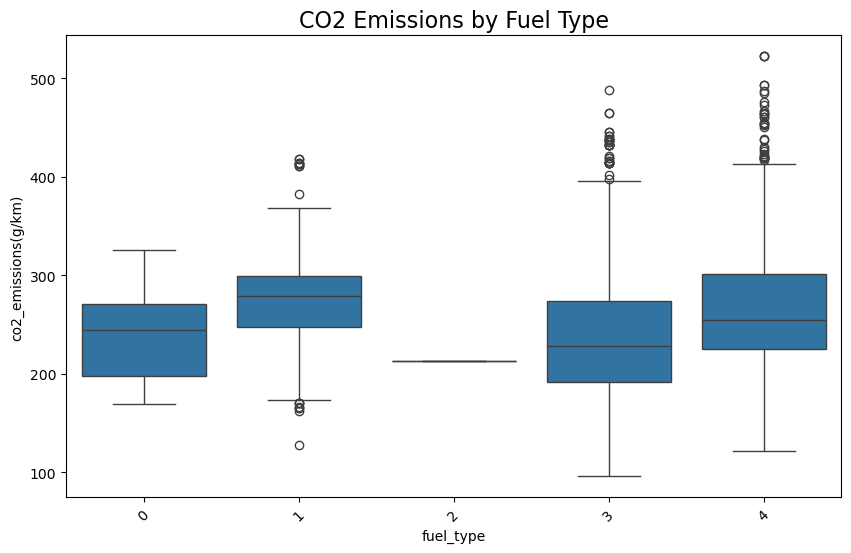

In [20]:
# Fuel Type vs CO2 Emissions
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x="fuel_type", y="co2_emissions(g/km)")
plt.title("CO2 Emissions by Fuel Type", fontsize=16)
plt.xticks(rotation=45)
plt.show()

<b>SCATTER PLOT</B>

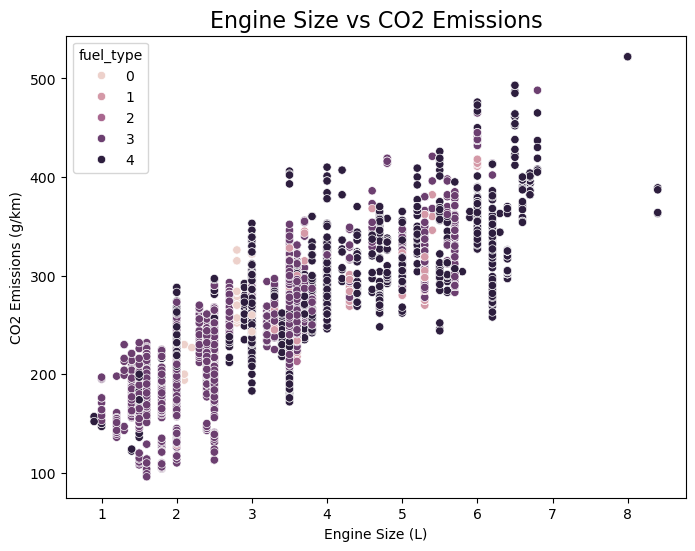

In [21]:
# Engine Size vs CO2 Emissions (scatter)
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x="engine_size(l)", y="co2_emissions(g/km)", hue="fuel_type")
plt.title("Engine Size vs CO2 Emissions", fontsize=16)
plt.xlabel("Engine Size (L)")
plt.ylabel("CO2 Emissions (g/km)")
plt.show()

<b>BAR PLOT</B>

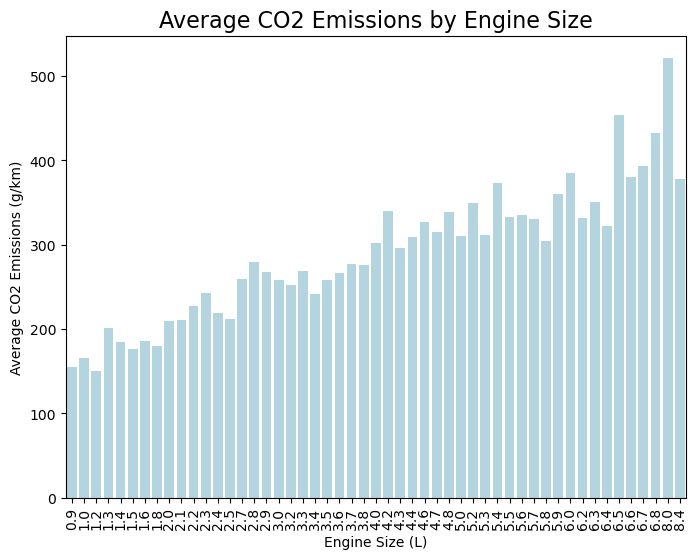

In [22]:
# Group data by engine size and calculate the average CO2 emissions
engine_co2_avg = df.groupby("engine_size(l)")["co2_emissions(g/km)"].mean().reset_index()

# Create the bar plot
plt.figure(figsize=(8,6))
sns.barplot(x="engine_size(l)", y="co2_emissions(g/km)", data=engine_co2_avg, color="lightblue")
plt.title("Average CO2 Emissions by Engine Size", fontsize=16)
plt.xlabel("Engine Size (L)")
plt.ylabel("Average CO2 Emissions (g/km)")

# Rotate x-axis labels downwards (90 degrees)
plt.xticks(rotation=90)

plt.show()


<h4><u><b>FEATURES AND TARGETS:</B></h4></u>

In [23]:
X=df.drop("co2_emissions(g/km)",axis=1)
y=df["co2_emissions(g/km)"]
y

0       196
1       221
2       136
3       255
4       244
       ... 
7380    219
7381    232
7382    240
7383    232
7384    248
Name: co2_emissions(g/km), Length: 7385, dtype: int64

In [24]:
X

,make,model,vehicle_class,engine_size(l),cylinders,transmission,fuel_type,fuel_consumption_city_(l/100_km),fuel_consumption_hwy_(l/100_km),fuel_consumption_comb_(l/100_km),fuel_consumption_comb_(mpg)
0,0,1057,0,2.0,4,14,4,9.9,6.7,8.5,33
1,0,1057,0,2.4,4,25,4,11.2,7.7,9.6,29
2,0,1058,0,1.5,4,22,4,6.0,5.8,5.9,48
3,0,1233,11,3.5,6,15,4,12.7,9.1,11.1,25
4,0,1499,11,3.5,6,15,4,12.1,8.7,10.6,27
...,...,...,...,...,...,...,...,...,...,...,...
7380,41,1951,11,2.0,4,17,4,10.7,7.7,9.4,30
7381,41,1957,11,2.0,4,17,4,11.2,8.3,9.9,29
7382,41,1960,11,2.0,4,17,4,11.7,8.6,10.3,27
7383,41,1968,12,2.0,4,17,4,11.2,8.3,9.9,29


<b><h4><u>MODEL SCALING ,SPLITTING AND TRAINING:</u></h4></b>

In [25]:
from sklearn.model_selection import train_test_split   
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

In [26]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

<ul><li><b>Linear Regression:</b></li></ul> <p>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<b>Linear Regression is a fundamental machine learning algorithm that models the relationship between a dependent variable and one or more independent variables by fitting a straight line. It assumes that the change in the output variable is proportional to the change in the input variables. Linear Regression is simple, fast, and serves as a good baseline for regression tasks, especially when the relationship between variables is approximately linear.</b></p>

In [27]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [28]:
y_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

In [29]:
accuracy=model.score(X_test,y_test)
accuracy

0.9125612688263743

In [30]:
r2=r2_score(y_train,y_train_pred)
r2


0.9167193578970774

In [31]:
mse=mean_squared_error(y_train,y_train_pred)
mse

286.68983205988235

In [32]:
mae=mean_absolute_error(y_train,y_train_pred)
mae

11.000123402015374

In [33]:
print("Accuracy of Linear Regression Model:",accuracy)
print("MSE of Linear Regression Model:",mse)
print("MAE of Linear Regression Model:",mae)
print("R2 Score of Linear Regression Model:",r2)

Accuracy of Linear Regression Model: 0.9125612688263743
MSE of Linear Regression Model: 286.68983205988235
MAE of Linear Regression Model: 11.000123402015374
R2 Score of Linear Regression Model: 0.9167193578970774


<ul><li><b>Random Forest Regressor:</b></li></ul> <p>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<b>Random Forest Regressor is an ensemble learning algorithm that combines multiple decision trees to improve predictive accuracy and reduce overfitting. Each tree is trained on a random subset of the data and features, and the final prediction is typically the average of all tree outputs. The randomness and ensemble strategy make Random Forest highly robust, stable, and effective for complex regression tasks with noisy data.</b></p>

In [34]:
from sklearn.model_selection import train_test_split   
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

In [35]:
from sklearn.ensemble import RandomForestRegressor

In [36]:
rfmodel=RandomForestRegressor()
rfmodel.fit(X_train,y_train)

RandomForestRegressor()

In [37]:
y_predicted=rfmodel.predict(X_test)
y_predicted

array([246.69333333, 131.00166667, 290.698     , ..., 420.08      ,
       294.16      , 170.95      ])

In [38]:
y_train_pred = rfmodel.predict(X_train)

In [39]:
accuracy=rfmodel.score(X_test,y_test)
accuracy

0.9978431525729679

In [40]:
r2=r2_score(y_train,y_train_pred)
r2

0.9994249727335394

In [41]:
mse=mean_squared_error(y_train,y_train_pred)
mse

1.9795052762406955

In [42]:
mae=mean_absolute_error(y_train,y_train_pred)
mae

0.7911657650021304

In [43]:
print("Accuracy of Random Forest Regressor Model:",accuracy)
print("MSE of Random Forest Regressor Model:",mse)
print("MAE of Random Forest Regressor Model:",mae)
print("R2 Score of Random Forest Regressor Model:",r2)

Accuracy of Random Forest Regressor Model: 0.9978431525729679
MSE of Random Forest Regressor Model: 1.9795052762406955
MAE of Random Forest Regressor Model: 0.7911657650021304
R2 Score of Random Forest Regressor Model: 0.9994249727335394


<ul><li><b>Decision Tree Regressor:</b></li></ul> <p>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<b>Decision Tree Regressor is a non-linear supervised learning algorithm that predicts continuous values by learning simple decision rules inferred from the data features. It splits the dataset into smaller subsets based on feature conditions, making the model flexible and capable of handling both linear and complex patterns. Decision Trees are easy to interpret and can capture relationships that are not easily modeled with linear methods.</b></p>

In [44]:
from sklearn.tree import DecisionTreeRegressor

In [45]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

In [46]:
dtr_model=DecisionTreeRegressor(random_state=101)
dtr_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=101)

In [47]:
y_pred=dtr_model.predict(X_test)

In [48]:
accuracy=dtr_model.score(X_test,y_test)
accuracy

0.996314399324622

In [49]:
r2=r2_score(y_test, y_pred)
r2

0.996314399324622

In [50]:
mse=mean_squared_error(y_test, y_pred)
mse

12.31611355600692

In [51]:
mae=mean_absolute_error(y_test,y_pred)
mae

1.752234258632363

In [52]:
print("Accuracy of Decision Tree Regressor Model:",accuracy)
print("MSE of Decision Tree Regressor Model:",mse)
print("MAE of Decision Tree Regression Model:",mae)
print("R2 Score of Decision Tree Regressor Model:",r2)

Accuracy of Decision Tree Regressor Model: 0.996314399324622
MSE of Decision Tree Regressor Model: 12.31611355600692
MAE of Decision Tree Regression Model: 1.752234258632363
R2 Score of Decision Tree Regressor Model: 0.996314399324622


__GRADIO__

In [53]:
pip install gradio

Note: you may need to restart the kernel to use updated packages.


In [57]:
import pickle
import os
model_file_name="rfr_best_model.pkl"
model_folder="./models/"
os.makedirs(model_folder,exist_ok=True)
with open(os.path.join(model_folder,model_file_name),"wb")as file:
    pickle.dump(rfmodel,file)
    

In [58]:
import gradio as gr
with open(os.path.join(model_folder,model_file_name),"rb")as file:
    model=pickle.load(file)

In [59]:
def predict(*args):
    input_data = pd.DataFrame([args], columns=['make', 'model', 'vehicle_class', 'engine_size(l)', 'cylinders',
       'transmission', 'fuel_type', 'fuel_consumption_city_(l/100_km)',
       'fuel_consumption_hwy_(l/100_km)', 'fuel_consumption_comb_(l/100_km)',
       'fuel_consumption_comb_(mpg)'])  
    prediction = model.predict(input_data)
    return prediction[0]

headline="CO2 Emission Predictor"
iface=gr.Interface(fn=predict,
                   inputs=[
                      gr.Number(label="Make"),
                      gr.Number(label="Model"),
                      gr.Number(label="Vehicle Class"),
                      gr.Number(label="Engine size"),
                      gr.Number(label="Cylinders"),
                      gr.Number(label="Transmission"),
                      gr.Number(label="Fuel type"),
                      gr.Number(label="fuel_consumption_city_(l/100_km)"),
                      gr.Number(label="fuel_consumption_hwy_(l/100_km)"),
                      gr.Number(label="fuel_consumption_comb_(l/100_km)"),
                      gr.Number(label="fuel_consumption_comb_(mpg)'")],
                      
                    outputs=gr.Textbox(label="Predicted Emission"),
                    title=headline)
iface.launch(share=True)
                             

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://d6458de20c23b1f41d.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


<b><h3>  <U>CONCLUSION:</U></h3></B>

 <p>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<b>In this project, Linear Regression, Decision Tree Regressor, and Random Forest Regressor were used to predict CO₂ emissions. All three models were compared based on their accuracy. Random Forest Regressor performed the best among the three, achieving an accuracy of 99.7%. Its ability to handle complex data patterns and reduce overfitting made it the most suitable model for this prediction task.</b></p>

<center><b><p style="font-family: 'Times New Roman', Times, serif;"><h2>  <U>END OF PROJECT</U></h2></B></center>